Fetching data for SUZLON.NS...
Available columns: ['Date', 'Close', 'High', 'Low', 'Open', 'Volume']


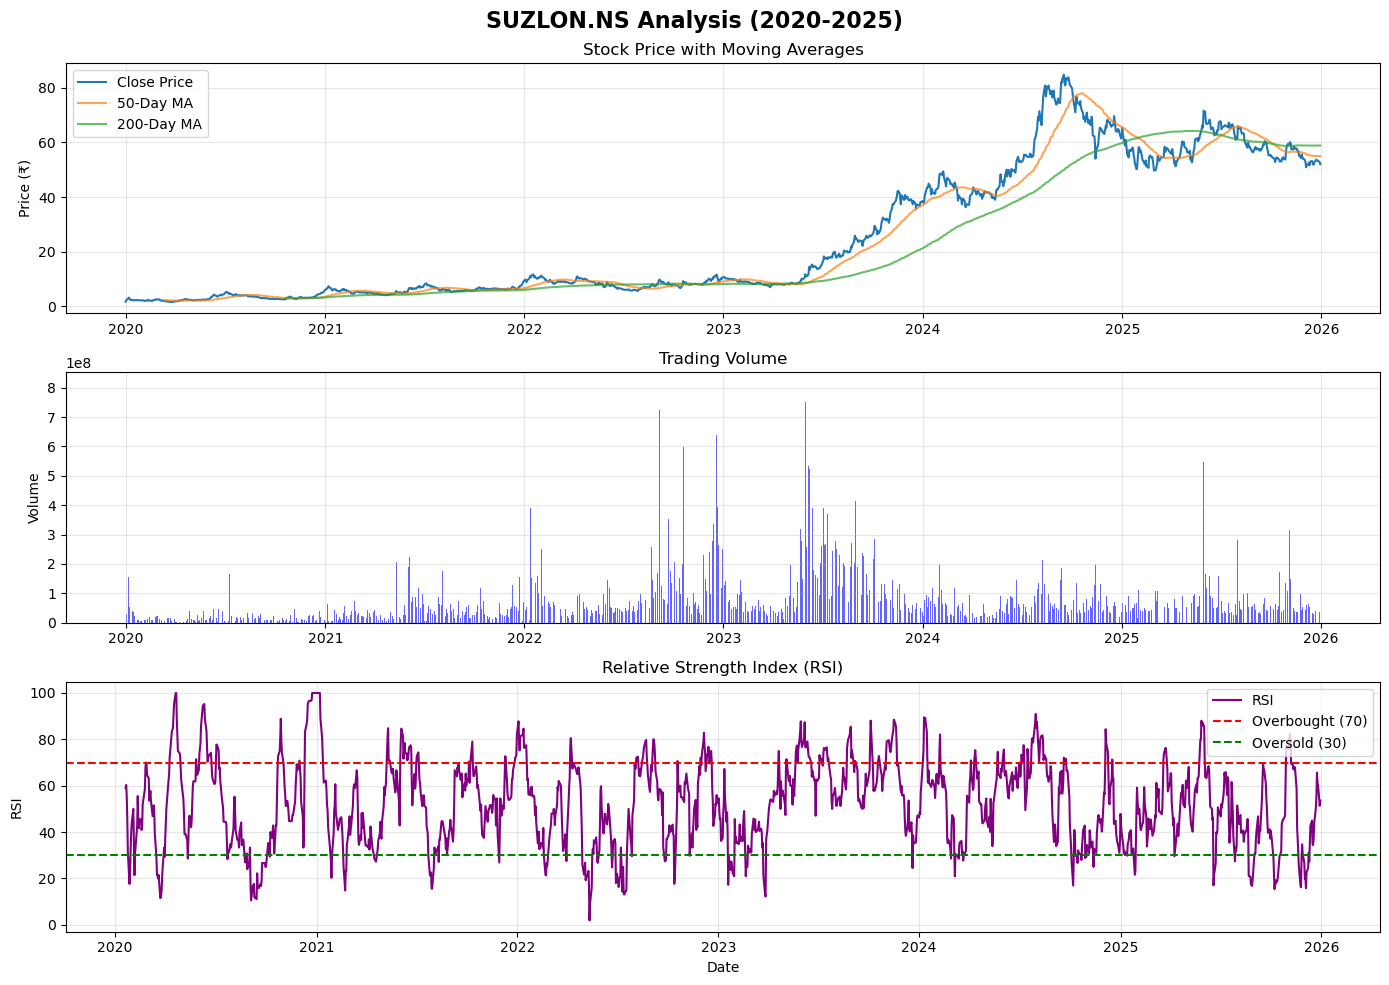


ANALYSIS SUMMARY FOR SUZLON.NS

Current Price: ₹52.00
52-Week High: ₹71.48
52-Week Low: ₹49.71
1-Year Return: -15.34%

50-Day MA: ₹54.94
200-Day MA: ₹58.82
Signal: BEARISH (Price below both MAs)

Current RSI: 53.58
RSI Signal: NEUTRAL

Annualized Volatility: 56.17%

INVESTMENT CONSIDERATIONS:
✓ Check if the stock is in an uptrend (price above MAs)
✓ RSI between 30-70 is generally favorable
✓ Compare returns with benchmark indices (Nifty 50)
✓ Consider company fundamentals and sector outlook
✓ Diversify your portfolio - don't invest everything in one stock

Note: This is technical analysis only. Always do thorough
fundamental analysis and consult a financial advisor before investing.


In [5]:
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from datetime import datetime

# Stock symbol - Change this to your desired NSE stock
# For NSE stocks, add .NS suffix (e.g., 'RELIANCE.NS', 'TCS.NS', 'INFY.NS')
STOCK_SYMBOL = 'SUZLON.NS'

# Fetch data from 2020 to 2025
start_date = '2020-01-01'
end_date = '2025-12-31'

print(f"Fetching data for {STOCK_SYMBOL}...")
stock_data = yf.download(STOCK_SYMBOL, start=start_date, end=end_date, progress=False)

if stock_data.empty:
    print("No data found. Please check the stock symbol.")
    exit()

# Handle MultiIndex columns if present
if isinstance(stock_data.columns, pd.MultiIndex):
    stock_data.columns = stock_data.columns.get_level_values(0)

# Reset index to make date a column
stock_data = stock_data.reset_index()

# Ensure we have the required columns
print("Available columns:", stock_data.columns.tolist())

# Calculate technical indicators
stock_data['MA50'] = stock_data['Close'].rolling(window=50).mean()
stock_data['MA200'] = stock_data['Close'].rolling(window=200).mean()
stock_data['Daily_Return'] = stock_data['Close'].pct_change()

# Calculate RSI (Relative Strength Index)
delta = stock_data['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
stock_data['RSI'] = 100 - (100 / (1 + rs))

# Create subplots
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
fig.suptitle(f'{STOCK_SYMBOL} Analysis (2020-2025)', fontsize=16, fontweight='bold')

# Plot 1: Price and Moving Averages
axes[0].plot(stock_data['Date'], stock_data['Close'], label='Close Price', linewidth=1.5)
axes[0].plot(stock_data['Date'], stock_data['MA50'], label='50-Day MA', linewidth=1.5, alpha=0.7)
axes[0].plot(stock_data['Date'], stock_data['MA200'], label='200-Day MA', linewidth=1.5, alpha=0.7)
axes[0].set_ylabel('Price (₹)')
axes[0].set_title('Stock Price with Moving Averages')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Volume
axes[1].bar(stock_data['Date'], stock_data['Volume'], alpha=0.6, color='blue')
axes[1].set_ylabel('Volume')
axes[1].set_title('Trading Volume')
axes[1].grid(True, alpha=0.3)

# Plot 3: RSI
axes[2].plot(stock_data['Date'], stock_data['RSI'], label='RSI', color='purple', linewidth=1.5)
axes[2].axhline(y=70, color='r', linestyle='--', label='Overbought (70)')
axes[2].axhline(y=30, color='g', linestyle='--', label='Oversold (30)')
axes[2].set_ylabel('RSI')
axes[2].set_xlabel('Date')
axes[2].set_title('Relative Strength Index (RSI)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Analysis Summary
print("\n" + "="*60)
print(f"ANALYSIS SUMMARY FOR {STOCK_SYMBOL}")
print("="*60)

current_price = stock_data['Close'].iloc[-1]
year_ago_price = stock_data['Close'].iloc[-252] if len(stock_data) > 252 else stock_data['Close'].iloc[0]
year_return = ((current_price - year_ago_price) / year_ago_price) * 100

print(f"\nCurrent Price: ₹{current_price:.2f}")
print(f"52-Week High: ₹{stock_data['Close'].tail(252).max():.2f}")
print(f"52-Week Low: ₹{stock_data['Close'].tail(252).min():.2f}")
print(f"1-Year Return: {year_return:.2f}%")

# Moving Average Analysis
ma50_current = stock_data['MA50'].iloc[-1]
ma200_current = stock_data['MA200'].iloc[-1]
print(f"\n50-Day MA: ₹{ma50_current:.2f}")
print(f"200-Day MA: ₹{ma200_current:.2f}")

if current_price > ma50_current > ma200_current:
    print("Signal: BULLISH (Price above both MAs)")
elif current_price < ma50_current < ma200_current:
    print("Signal: BEARISH (Price below both MAs)")
else:
    print("Signal: NEUTRAL (Mixed signals)")

# RSI Analysis
current_rsi = stock_data['RSI'].iloc[-1]
print(f"\nCurrent RSI: {current_rsi:.2f}")
if current_rsi > 70:
    print("RSI Signal: OVERBOUGHT (Consider waiting)")
elif current_rsi < 30:
    print("RSI Signal: OVERSOLD (Potential buying opportunity)")
else:
    print("RSI Signal: NEUTRAL")

# Volatility
volatility = stock_data['Daily_Return'].std() * np.sqrt(252) * 100
print(f"\nAnnualized Volatility: {volatility:.2f}%")

# Overall Assessment
print("\n" + "="*60)
print("INVESTMENT CONSIDERATIONS:")
print("="*60)
print("✓ Check if the stock is in an uptrend (price above MAs)")
print("✓ RSI between 30-70 is generally favorable")
print("✓ Compare returns with benchmark indices (Nifty 50)")
print("✓ Consider company fundamentals and sector outlook")
print("✓ Diversify your portfolio - don't invest everything in one stock")
print("\nNote: This is technical analysis only. Always do thorough")
print("fundamental analysis and consult a financial advisor before investing.")
print("="*60)